# Predicción de la mortalidad por insuficiencia cardíaca

En este notebook se intenta predecir si un paciente con insuficiencia cardíaca fallece durante el periodo de seguimiento (`DEATH_EVENT`) a partir de sus datos clínicos. Se usa el conjunto de datos [Heart Failure Clinical Records](https://archive.ics.uci.edu/dataset/519/heart+failure+clinical+records) del repositorio UCI: 299 pacientes, 12 variables clínicas y ningún valor ausente.

Se comparan tres modelos lineales de clasificación con supuestos distintos:

1. **Naive Bayes gaussiano**: modelo generativo que supone que las variables son independientes y normales dentro de cada clase.
2. **Análisis discriminante lineal (LDA)**: modelo generativo que supone normalidad multivariante con una covarianza común a las dos clases, por lo que sí tiene en cuenta las correlaciones.
3. **Regresión logística**: modelo discriminativo que no supone nada sobre la distribución de las variables. Se prueba con y sin ponderación de clases.

Cada modelo se ajusta sobre dos versiones de los datos: la original y otra en la que las variables más asimétricas se transforman con el logaritmo.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import f1_score
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from sklearn.model_selection import cross_val_score
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression

In [2]:
df = pd.read_csv("heart_failure_clinical_records_dataset.csv")
df.head()

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


In [3]:
df.columns

Index(['age', 'anaemia', 'creatinine_phosphokinase', 'diabetes',
       'ejection_fraction', 'high_blood_pressure', 'platelets',
       'serum_creatinine', 'serum_sodium', 'sex', 'smoking', 'time',
       'DEATH_EVENT'],
      dtype='str')

In [4]:
df["DEATH_EVENT"].value_counts()

DEATH_EVENT
0    203
1     96
Name: count, dtype: int64

La variable objetivo está desbalanceada: un 68 % de los pacientes no fallece y un 32 % sí. Por eso la *accuracy* no es una buena métrica, ya que un modelo que siempre prediga "no fallece" acertaría el 68 % de las veces sin detectar ningún caso.

En todo el notebook se usa el **F1 de la clase "fallece"**, que combina precisión y recall. Si el modelo deja escapar a los pacientes que fallecen, el F1 lo refleja.

## Descripción de las variables

| Variable | Tipo | Descripción |
|---|---|---|
| `age` | Numérica | Edad del paciente |
| `anaemia` | Binaria | Si el paciente tiene anemia |
| `creatinine_phosphokinase` | Numérica | Nivel de la enzima CPK en sangre |
| `diabetes` | Binaria | Si el paciente tiene diabetes |
| `ejection_fraction` | Numérica | Porcentaje de sangre que expulsa el corazón en cada contracción |
| `high_blood_pressure` | Binaria | Si el paciente tiene hipertensión |
| `platelets` | Numérica | Cantidad de plaquetas en sangre |
| `serum_creatinine` | Numérica | Nivel de creatinina en sangre |
| `serum_sodium` | Numérica | Nivel de sodio en sangre |
| `sex` | Binaria | Sexo del paciente |
| `smoking` | Binaria | Si el paciente fuma |
| `time` | Numérica | Días de seguimiento del paciente |
| `DEATH_EVENT` | Binaria | **Variable objetivo**: 1 si el paciente fallece durante el seguimiento |

Según la documentación del conjunto de datos no hay valores ausentes. Lo comprobamos:

In [5]:
df.isna().sum()

age                         0
anaemia                     0
creatinine_phosphokinase    0
diabetes                    0
ejection_fraction           0
high_blood_pressure         0
platelets                   0
serum_creatinine            0
serum_sodium                0
sex                         0
smoking                     0
time                        0
DEATH_EVENT                 0
dtype: int64

No hay ningún valor ausente, así que no hace falta imputar.

## 1. Preprocesamiento y análisis exploratorio

### Eliminación de `time`

`time` es la duración del seguimiento. Los pacientes que fallecen pronto tienen, por construcción, un seguimiento corto, de modo que esta variable contiene información sobre el desenlace que no estaría disponible al hacer una predicción real. Mantenerla supondría una **fuga de información**, así que la eliminamos antes de cualquier análisis.

In [6]:
df = df.drop(columns="time")
df

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...
294,62.0,0,61,1,38,1,155000.00,1.1,143,1,1,0
295,55.0,0,1820,0,38,0,270000.00,1.2,139,0,0,0
296,45.0,0,2060,1,60,0,742000.00,0.8,138,0,0,0
297,45.0,0,2413,0,38,0,140000.00,1.4,140,1,1,0


### Partición en entrenamiento y test

Dividimos los datos en entrenamiento (70 %) y test (30 %). La partición se **estratifica** según `DEATH_EVENT` para que los dos conjuntos mantengan la misma proporción de clases, y se fija la semilla para que los resultados sean reproducibles.

In [7]:
X = df.drop(columns="DEATH_EVENT")
Y = df["DEATH_EVENT"]
X_entr, X_test, Y_entr, Y_test = train_test_split(X, Y, test_size=0.3, stratify = Y, random_state=1)

In [8]:
display(X_entr)
display(Y_entr)

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking
262,65.0,1,258,1,25,0,198000.00,1.40,129,1,0
52,60.0,0,3964,1,62,0,263358.03,6.80,146,0,0
30,94.0,0,582,1,38,1,263358.03,1.83,134,1,0
12,45.0,1,981,0,30,0,136000.00,1.10,137,1,0
213,48.0,1,131,1,30,1,244000.00,1.60,130,0,0
...,...,...,...,...,...,...,...,...,...,...,...
65,60.0,0,68,0,20,0,119000.00,2.90,127,1,1
51,53.0,1,91,0,20,1,418000.00,1.40,139,0,0
19,48.0,1,582,1,55,0,87000.00,1.90,121,0,0
43,72.0,0,127,1,50,1,218000.00,1.00,134,1,0


262    1
52     1
30     1
12     1
213    1
      ..
65     1
51     1
19     1
43     0
161    0
Name: DEATH_EVENT, Length: 209, dtype: int64

Comprobamos que la estratificación ha mantenido la proporción de clases en ambos conjuntos:

In [9]:
display(Y_entr.value_counts())
display(Y_test.value_counts())
print(Y_entr.size)
print(Y_test.size)

DEATH_EVENT
0    142
1     67
Name: count, dtype: int64

DEATH_EVENT
0    61
1    29
Name: count, dtype: int64

209
90


En los dos conjuntos hay aproximadamente un 68 % de pacientes que no fallecen y un 32 % que sí, igual que en el conjunto completo. La estratificación es correcta: 209 pacientes en entrenamiento y 90 en test.

### Distribución de las variables explicativas

Analizamos con histogramas las variables numéricas no binarias del conjunto de entrenamiento. Las binarias se dejan fuera de este análisis, ya que solo toman dos valores y nunca pueden seguir una distribución normal.

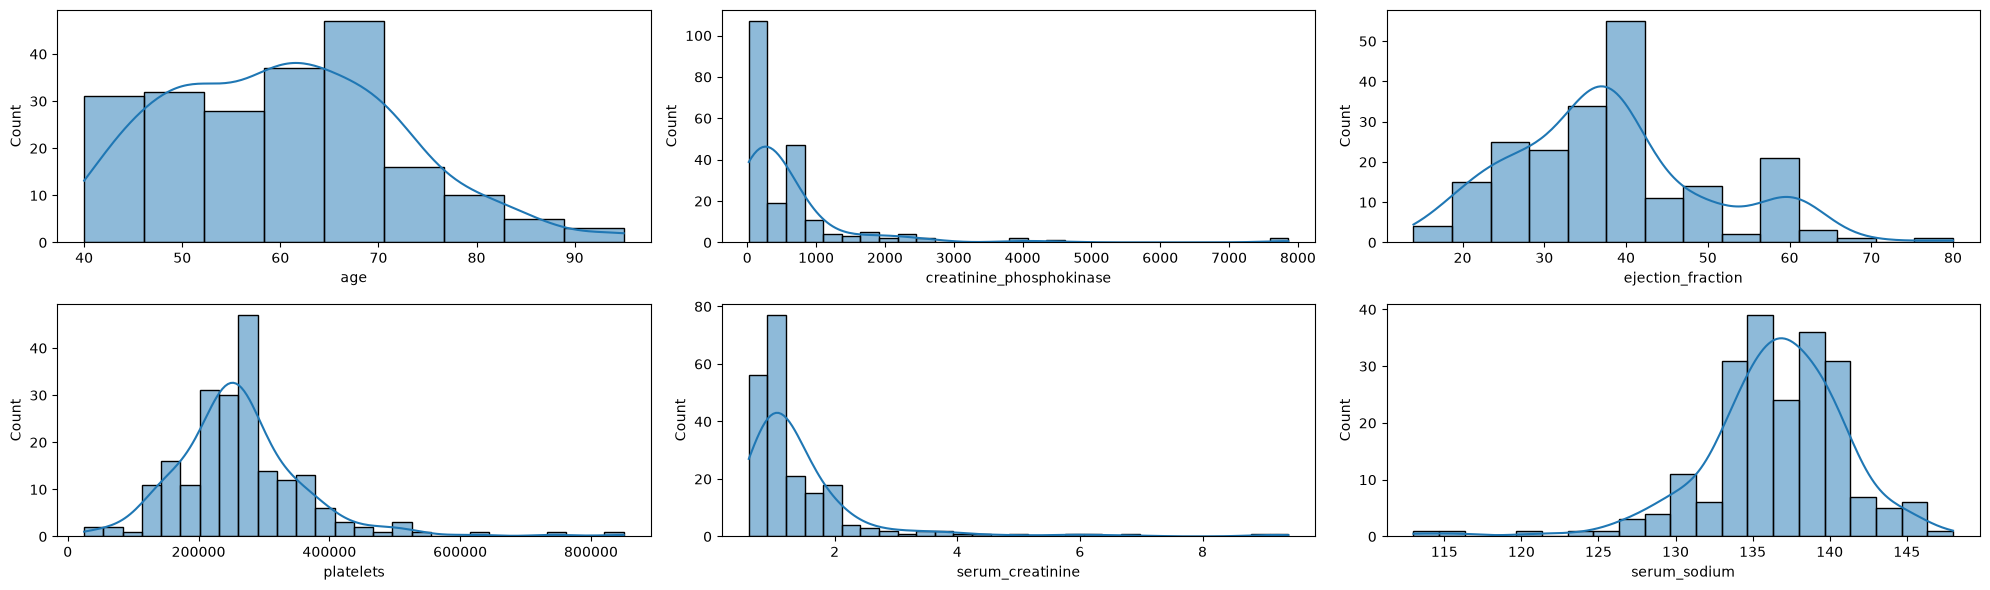

In [10]:
explicativas_no_binarias = ["age", "creatinine_phosphokinase", "ejection_fraction", "platelets", "serum_creatinine", "serum_sodium"]
fig, ejes = plt.subplots(2, 3, figsize=(20,6))
for variable, j in zip(explicativas_no_binarias, ejes.flatten()): 
    j.set_xlabel(variable)
    sns.histplot(x=X_entr[variable], ax=j, kde=True)
fig.tight_layout()
plt.show()

Ninguna variable es claramente normal:

- `age` y `ejection_fraction` se alejan de la normalidad; `ejection_fraction` incluso parece bimodal.
- `platelets` se parece bastante a una normal, aunque con algo de asimetría a la derecha.
- `serum_sodium` tiene una cola hacia la izquierda.
- `creatinine_phosphokinase` y `serum_creatinine` tienen una asimetría positiva muy fuerte, con una cola larga a la derecha.

Veamos cómo quedan todas después de aplicar el logaritmo:

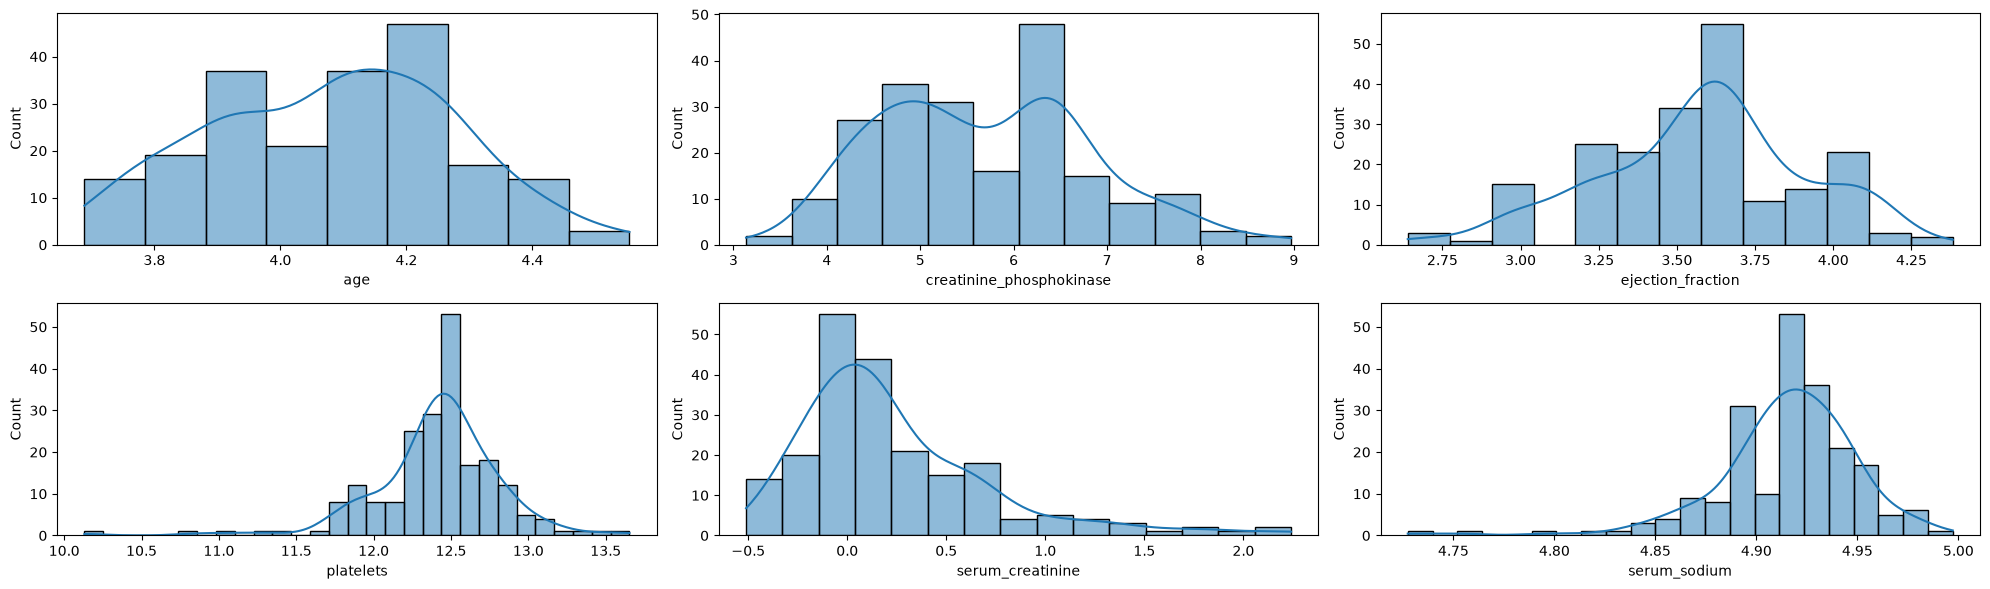

In [11]:
fig, ejes = plt.subplots(2, 3, figsize=(20,6))
for variable, j in zip(explicativas_no_binarias, ejes.flatten()): 
    j.set_xlabel(variable)
    sns.histplot(x=np.log(X_entr[variable]), ax=j, kde=True)
fig.tight_layout()
plt.show()

Aplicamos el logaritmo **solo a las variables que se desvían mucho de la normalidad**:

- **Con logaritmo:** `creatinine_phosphokinase` y `serum_creatinine`. Su fuerte asimetría positiva se reduce mucho y quedan bastante más cerca de una normal, aunque sin llegar a serlo del todo.
- **Sin logaritmo:** `age`, `ejection_fraction`, `platelets` y `serum_sodium`. Su desviación de la normalidad es moderada y el logaritmo no la mejora: en `ejection_fraction` y `platelets` desplaza la cola hacia la izquierda, y en `serum_sodium` no corrige su asimetría negativa.

A partir de aquí trabajamos con dos conjuntos: el **original** y el **logarítmico**. La transformación se aplica por igual a entrenamiento y a test.

In [12]:
X_entr_log = X_entr.copy()
X_test_log = X_test.copy()

X_entr_log["creatinine_phosphokinase"] = np.log(X_entr_log["creatinine_phosphokinase"])
X_entr_log["serum_creatinine"] = np.log(X_entr_log["serum_creatinine"])

X_test_log["creatinine_phosphokinase"] = np.log(X_test_log["creatinine_phosphokinase"])
X_test_log["serum_creatinine"] = np.log(X_test_log["serum_creatinine"])

### Correlaciones

La variable objetivo es binaria, así que no hace falta describir su distribución más allá del desbalanceo ya comentado. Calculamos dos tipos de correlación:

- **Pearson**, que mide relación lineal. La calculamos con los datos originales y con los logarítmicos.
- **Spearman**, que mide relación monótona a partir de los rangos. Es robusta a valores extremos y no le afecta el logaritmo.

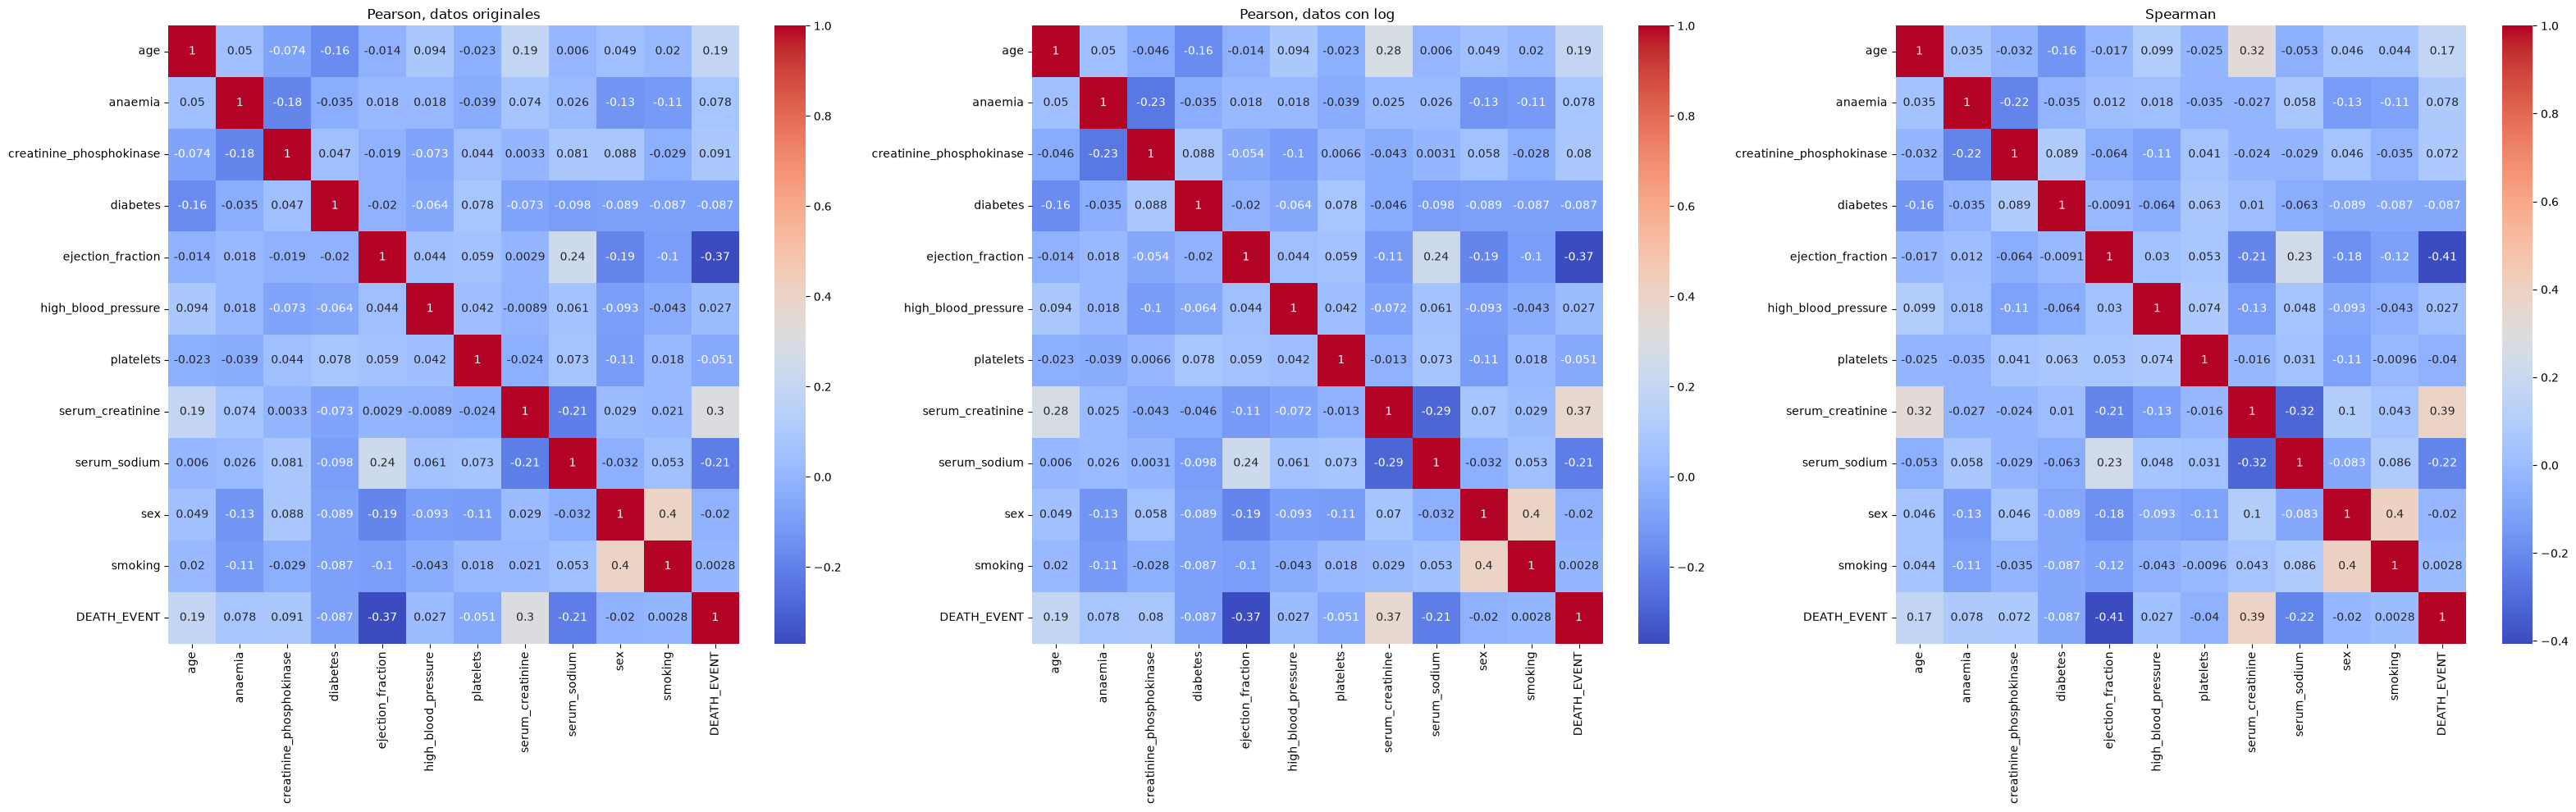

In [13]:
datos = pd.concat([X_entr, Y_entr], axis=1)
datos_log = pd.concat([X_entr_log, Y_entr], axis=1)

fig, ejes = plt.subplots(1, 3, figsize=(32, 10))
sns.heatmap(datos.corr(method="pearson"), annot=True, cmap="coolwarm", ax=ejes[0])
ejes[0].set_title("Pearson, datos originales")
sns.heatmap(datos_log.corr(method= "pearson"), annot=True, cmap="coolwarm", ax=ejes[1])
ejes[1].set_title("Pearson, datos con log")
sns.heatmap(datos.corr(method= "spearman"), annot=True, cmap="coolwarm", ax=ejes[2])
ejes[2].set_title("Spearman")
plt.tight_layout()
plt.show()

Con cualquier coeficiente y con o sin logaritmo, las variables más relacionadas con `DEATH_EVENT` son las mismas. Ordenadas por valor absoluto:

1. `ejection_fraction` (negativa: cuanto menor es, más riesgo).
2. `serum_creatinine` (positiva).
3. `serum_sodium` (negativa).
4. `age` (positiva).

Lo único que cambia es la magnitud de la correlación de `serum_creatinine`: con el logaritmo se acerca a la de Spearman, porque se reduce el efecto de sus valores extremos.

Aun así, todas las correlaciones son débiles o moderadas, y entre variables explicativas también son bajas; la mayor es la de `sex` con `smoking`. Esto anticipa un problema difícil: probablemente el desenlace depende de varias variables a la vez y no de una sola.

### Estandarización

Estandarizamos los dos conjuntos con la media y la desviación típica calculadas **solo con los datos de entrenamiento**, y aplicamos la misma transformación al test. La estandarización no requiere que las variables sean normales.

Naive Bayes y LDA no se ven afectados por la escala, pero la regresión logística regularizada sí, porque la penalización actúa sobre el tamaño de los coeficientes. Además, así los coeficientes de los distintos modelos se pueden comparar entre variables.

In [14]:
scaler = StandardScaler()
X_entr = scaler.fit_transform(X_entr)
X_test = scaler.transform(X_test)

X_entr_log = scaler.fit_transform(X_entr_log)
X_test_log = scaler.transform(X_test_log)

In [15]:
display(X_entr.std())
display(X_entr.mean().round(2))
display(X_entr_log.std())
display(X_entr_log.mean().round(2))


np.float64(1.0)

np.float64(-0.0)

np.float64(1.0)

np.float64(-0.0)

Las variables quedan con media 0 y desviación típica 1, así que la estandarización es correcta.

## 2. Naive Bayes gaussiano

Naive Bayes aplica el teorema de Bayes suponiendo que, dentro de cada clase, las variables son independientes y siguen una distribución normal. No tiene hiperparámetros que ajustar.

**Cómo se evalúan todos los modelos del notebook:**

- El **error de generalización** se estima con **validación cruzada de 10 particiones** sobre entrenamiento, con la media y la desviación típica del F1. Esta media es el único criterio para comparar modelos.
- El **test** solo se usa para detectar sobreajuste: su F1 debe quedar dentro de la distribución de la validación cruzada. Lo medimos con $z = (F1_{test} - \bar{F1}_{CV}) / s_{CV}$ y consideramos normal que $|z| < 2$.

In [16]:
gnb = GaussianNB()
res_f1 = cross_val_score(gnb, X_entr, Y_entr, cv=10, scoring="f1")

gnb_log = GaussianNB()
res_f1_log = cross_val_score(gnb_log, X_entr_log, Y_entr, cv=10, scoring="f1")
print(f"f1 medio del modelo original: {res_f1.mean().round(3)} con una std: {res_f1.std().round(3)}")
print(f"f1 medio del modelo log: {res_f1_log.mean().round(3)} con una std: {res_f1_log.std().round(3)}")

f1 medio del modelo original: 0.401 con una std: 0.198
f1 medio del modelo log: 0.553 con una std: 0.146


In [17]:
gnb.fit(X_entr, Y_entr)
gnb_log.fit(X_entr_log, Y_entr)
print(f"Original vs test: {f1_score(Y_test, gnb.predict(X_test)):.3f}")
print(f"Log vs test: {f1_score(Y_test, gnb_log.predict(X_test_log)):.3f}")

Original vs test: 0.167
Log vs test: 0.400


Naive Bayes no funciona bien en este problema:

- Con los datos originales el F1 es muy bajo (0.401). Las colas largas de `creatinine_phosphokinase` y `serum_creatinine` hacen que las campanas gaussianas se ajusten mal, y el modelo predice casi siempre "no fallece".
- El logaritmo mejora mucho el resultado (0.553), lo que confirma que la asimetría era un problema importante para este modelo.
- El supuesto de independencia no se cumple del todo, pero las correlaciones entre variables son débiles, así que no parece la causa principal.

El F1 en test (0.167 y 0.400) queda dentro de la distribución de la validación cruzada (z ≈ −1.2 y −1.0), por lo que no hay sobreajuste. El problema es que el modelo es demasiado simple para separar bien las clases.

## 3. Análisis discriminante lineal (LDA)

LDA también es un modelo generativo, pero no supone independencia: modela cada clase con una normal multivariante y una matriz de covarianza común, de modo que tiene en cuenta las correlaciones entre variables. Al compartir la covarianza, la frontera entre las clases es lineal.

In [18]:
lda = LinearDiscriminantAnalysis()
res_f1_lda = cross_val_score(lda, X_entr, Y_entr, cv=10, scoring="f1")

lda_log = LinearDiscriminantAnalysis()
res_f1_lda_log = cross_val_score(lda_log, X_entr_log, Y_entr, cv=10, scoring="f1")
print(f"F1 medio LDA original: {res_f1_lda.mean().round(3)} con una std: {res_f1_lda.std().round(3)}")
print(f"F1 medio LDA log: {res_f1_lda_log.mean().round(3)} con una std: {res_f1_lda_log.std().round(3)}")

F1 medio LDA original: 0.584 con una std: 0.194
F1 medio LDA log: 0.571 con una std: 0.187


In [19]:
lda.fit(X_entr, Y_entr)
lda_log.fit(X_entr_log, Y_entr)
print(f"LDA original vs test: {f1_score(Y_test, lda.predict(X_test)):.3f}")
print(f"LDA log vs test: {f1_score(Y_test, lda_log.predict(X_test_log)):.3f}")

LDA original vs test: 0.293
LDA log vs test: 0.489


- **Con los datos originales**, LDA mejora claramente a Naive Bayes (0.584 frente a 0.401). Al usar una covarianza común y una frontera lineal, es menos sensible a la asimetría de `creatinine_phosphokinase` y `serum_creatinine`.
- **Con logaritmo**, los dos modelos quedan prácticamente igual (0.571 frente a 0.553). Como las correlaciones entre variables son débiles, tenerlas en cuenta aporta poco una vez corregida la asimetría.
- En LDA, el logaritmo apenas cambia el resultado en validación cruzada (0.584 frente a 0.571).

En test, el modelo original obtiene un resultado más bajo (0.293 frente a 0.489 con logaritmo), pero los dos quedan dentro de la distribución de la validación cruzada (z ≈ −1.5 y −0.4), así que no hay sobreajuste. El rendimiento sigue siendo bajo.

In [20]:
lda_modelo = LinearDiscriminantAnalysis().fit(X_entr, Y_entr)
print(f"No fallece {lda_modelo.priors_[0]}, fallece {lda_modelo.priors_[1]}")
display(pd.DataFrame(lda_modelo.coef_, columns=X.columns))
display(pd.DataFrame(lda_modelo.means_, columns=X.columns))

No fallece 0.6794258373205742, fallece 0.32057416267942584


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking
0,0.416956,0.204633,0.396756,-0.217921,-1.099428,0.098722,-0.075381,0.748442,-0.288637,-0.364969,0.055986


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking
0,-0.133694,-0.053778,-0.062562,0.060057,0.253825,-0.018812,0.034761,-0.207806,0.143838,0.014049,-0.001918
1,0.283352,0.113978,0.132594,-0.127284,-0.537957,0.039871,-0.073673,0.440425,-0.304851,-0.029776,0.004065


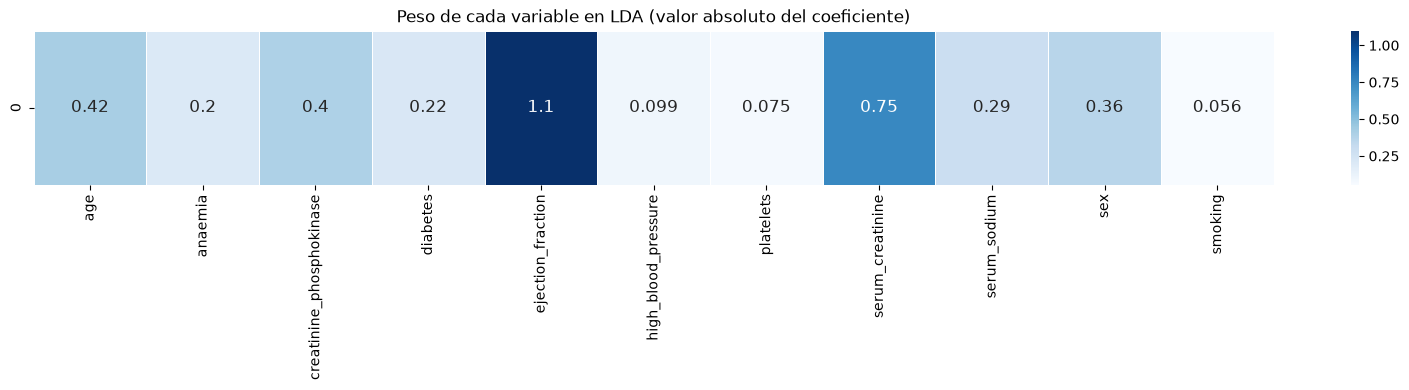

In [ ]:
coefs = pd.DataFrame(lda_modelo.coef_)
coefs.columns = X.columns

plt.figure(figsize=(20,2))
sns.heatmap(coefs.abs(), annot=True, linewidths=.5, cbar=True, xticklabels=True, cmap='Blues', annot_kws={'size':12})
plt.title("Peso de cada variable en LDA (valor absoluto del coeficiente)")
plt.show()

- **Priors:** reflejan el desbalanceo (68 % no fallece y 32 % fallece), lo que empuja al modelo a predecir "no fallece".
- **Coeficientes:** como los datos están estandarizados, se pueden comparar entre sí. Las variables con más peso son `ejection_fraction` (−1.10, la mayor en valor absoluto: cuanto menor es la fracción de eyección, mayor es el riesgo) y `serum_creatinine` (0.75), seguidas de `age` y `creatinine_phosphokinase`. `smoking`, `platelets` y `high_blood_pressure` apenas influyen.
- **Medias por clase:** ninguna variable separa a los pacientes que fallecen de los que no en más de una desviación típica. Las dos clases se solapan mucho, por lo que es difícil separarlas con una frontera lineal.

## 4. Regresión logística

El conjunto de datos mezcla variables continuas y binarias. Las binarias nunca pueden ser normales, así que los supuestos de los modelos generativos no se cumplen del todo. La regresión logística es un modelo **discriminativo**: modela directamente la probabilidad de fallecer sin suponer nada sobre la distribución de las variables.

Exploramos sus hiperparámetros con una búsqueda en rejilla y validación cruzada de 10 particiones:

- **Penalización:** `l1`, que puede anular coeficientes y por tanto eliminar variables, o `l2`, que los reduce sin anularlos.
- **`C`:** 21 valores entre $10^{-3}$ y $10^{3}$ en escala logarítmica. Cuanto menor es `C`, más fuerte es la regularización.

Usamos el *solver* `liblinear` porque el que viene por defecto no admite la penalización `l1`.

In [21]:
lr= LogisticRegression(max_iter=10000, solver="liblinear")
param = {'penalty': ['l1', 'l2'], 'C':10**np.linspace(-3,3,21, endpoint=True)}
lr_gs =  GridSearchCV(lr, param,cv=10, n_jobs=-1, refit=True, scoring="f1")
lr_gs.fit(X_entr, Y_entr);
lr_gs_log =  GridSearchCV(lr, param,cv=10, n_jobs=-1, refit=True, scoring="f1")
lr_gs_log.fit(X_entr_log, Y_entr);

In [22]:
print(f"LR original: {lr_gs.best_params_}  F1 medio: {lr_gs.best_score_:.3f} std: {lr_gs.cv_results_["std_test_score"][lr_gs.best_index_].round(3)}")
print(f"LR log: {lr_gs_log.best_params_}  F1 medio: {lr_gs_log.best_score_:.3f} std: {lr_gs_log.cv_results_["std_test_score"][lr_gs_log.best_index_].round(3)}")

LR original: {'C': np.float64(3.981071705534969), 'penalty': 'l2'}  F1 medio: 0.624 std: 0.177
LR log: {'C': np.float64(0.0630957344480193), 'penalty': 'l2'}  F1 medio: 0.612 std: 0.151


En los dos conjuntos la mejor penalización es `l2`. La regresión logística mejora ligeramente a los modelos generativos: un F1 de 0.624 frente a 0.584 de LDA y 0.401 de Naive Bayes con los datos originales, y de 0.612 frente a 0.571 y 0.553 con logaritmo.

Como no supone normalidad, el logaritmo apenas cambia el resultado (0.624 frente a 0.612).

In [23]:
print(f"LR original vs test: {f1_score(Y_test, lr_gs.predict(X_test)):.3f}")
print(f"LR log vs test: {f1_score(Y_test, lr_gs_log.predict(X_test_log)):.3f}")

LR original vs test: 0.333
LR log vs test: 0.478


In [24]:
print(classification_report(Y_test, lr_gs.predict(X_test), target_names=['No fallece', 'Fallece']))


              precision    recall  f1-score   support

  No fallece       0.71      0.90      0.80        61
     Fallece       0.54      0.24      0.33        29

    accuracy                           0.69        90
   macro avg       0.63      0.57      0.57        90
weighted avg       0.66      0.69      0.65        90



In [25]:
print(classification_report(Y_test, lr_gs_log.predict(X_test_log), target_names=['No fallece', 'Fallece']))

              precision    recall  f1-score   support

  No fallece       0.75      0.90      0.82        61
     Fallece       0.65      0.38      0.48        29

    accuracy                           0.73        90
   macro avg       0.70      0.64      0.65        90
weighted avg       0.72      0.73      0.71        90



El F1 en test (0.333 y 0.478) es inferior al de validación cruzada, pero queda dentro de su distribución (z ≈ −1.6 y −0.9), así que no hay un sobreajuste claro. El test solo contiene 29 pacientes que fallecen, por lo que unos pocos aciertos más o menos cambian mucho el F1; con más datos las métricas serían más estables.

El informe de clasificación muestra cuál es el problema: el recall de la clase "fallece" es bajo (0.24 en el modelo original), porque el modelo sigue favoreciendo a la clase mayoritaria.

Por otro lado, todos los modelos anteriores también obtienen en test un resultado algo inferior al de validación cruzada, lo que sugiere que esta partición de test es, por azar, algo más difícil que la media de los folds.

### Regresión logística con pesos de clase

Las clases están desbalanceadas y lo que más nos importa es detectar a los pacientes que fallecen. Con `class_weight="balanced"`, cada clase recibe un peso inversamente proporcional a su frecuencia, $\omega_k = n / (2\, n_k)$: unos 0.74 para "no fallece" y 1.56 para "fallece". Así, equivocarse con un paciente que fallece cuesta aproximadamente el doble. Repetimos la misma búsqueda de hiperparámetros con este parámetro.

In [26]:
lr_bal= LogisticRegression(max_iter=10000, solver="liblinear", class_weight="balanced")
param = {'penalty': ['l1', 'l2'], 'C':10**np.linspace(-3,3,21, endpoint=True)}
lr_bal_gs =  GridSearchCV(lr_bal, param,cv=10, n_jobs=-1, refit=True, scoring="f1")
lr_bal_gs.fit(X_entr, Y_entr);
lr_bal_gs_log =  GridSearchCV(lr_bal, param,cv=10, n_jobs=-1, refit=True, scoring="f1")
lr_bal_gs_log.fit(X_entr_log, Y_entr);

In [27]:
print(f"LR balanced original: {lr_bal_gs.best_params_}  F1 medio: {lr_bal_gs.best_score_:.3f} std: {lr_bal_gs.cv_results_["std_test_score"][lr_bal_gs.best_index_].round(3)}")
print(f"LR balanced log: {lr_bal_gs_log.best_params_}  F1 medio: {lr_bal_gs_log.best_score_:.3f} std: {lr_bal_gs_log.cv_results_["std_test_score"][lr_bal_gs_log.best_index_].round(3)}")

LR balanced original: {'C': np.float64(0.25118864315095796), 'penalty': 'l1'}  F1 medio: 0.663 std: 0.114
LR balanced log: {'C': np.float64(0.0630957344480193), 'penalty': 'l1'}  F1 medio: 0.659 std: 0.12


In [28]:
print(f"LR balanced original vs test: {f1_score(Y_test, lr_bal_gs.predict(X_test)):.3f}")
print(f"LR balanced log vs test: {f1_score(Y_test, lr_bal_gs_log.predict(X_test_log)):.3f}")

LR balanced original vs test: 0.548
LR balanced log vs test: 0.531


In [29]:
print(classification_report(Y_test, lr_bal_gs.predict(X_test), target_names=['No fallece', 'Fallece']))


              precision    recall  f1-score   support

  No fallece       0.79      0.74      0.76        61
     Fallece       0.52      0.59      0.55        29

    accuracy                           0.69        90
   macro avg       0.65      0.66      0.66        90
weighted avg       0.70      0.69      0.69        90



In [30]:
print(classification_report(Y_test, lr_bal_gs_log.predict(X_test_log), target_names=['No fallece', 'Fallece']))

              precision    recall  f1-score   support

  No fallece       0.78      0.70      0.74        61
     Fallece       0.49      0.59      0.53        29

    accuracy                           0.67        90
   macro avg       0.63      0.65      0.64        90
weighted avg       0.69      0.67      0.67        90



Con los pesos de clase, el F1 medio en validación cruzada mejora a **0.663** con los datos originales y a **0.659** con logaritmo, frente a 0.624 y 0.612 sin ponderar, y además la desviación entre folds es menor.

Al penalizar más los errores en la clase minoritaria, el modelo predice "fallece" con más facilidad: el recall de esta clase sube de 0.24–0.38 a 0.59, a cambio de algo de precisión. Como el recall era su punto débil, el F1 mejora. Ahora la mejor penalización es `l1`.

El F1 en test (0.548 y 0.531) sigue siendo algo menor, pero dentro de lo esperado (z ≈ −1.0 y −1.1), así que no hay sobreajuste.

In [31]:
coeficientes = pd.DataFrame(lr_bal_gs.best_estimator_.coef_)
coeficientes.columns = X.columns
coeficientes_log = pd.DataFrame(lr_bal_gs_log.best_estimator_.coef_)
coeficientes_log.columns = X.columns
display(coeficientes)
display(coeficientes_log)

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking
0,0.305608,0.08597,0.181828,-0.067385,-0.924611,0.0,0.0,0.636089,-0.136304,-0.209824,0.0


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking
0,0.0,0.0,0.0,0.0,-0.467064,0.0,0.0,0.434932,0.0,0.0,0.0


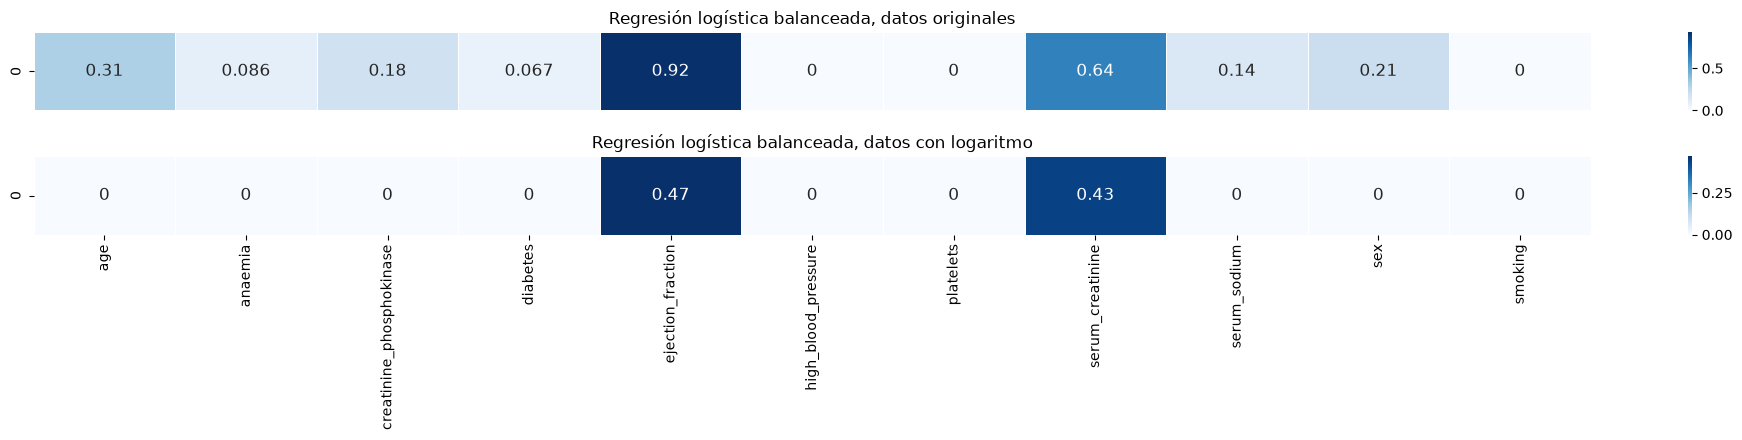

In [ ]:
fig, ejes = plt.subplots(2, 1, figsize=(20, 4.5))
sns.heatmap(coeficientes.abs(), annot=True, linewidths=.5, cbar=True, xticklabels=False, cmap='Blues', annot_kws={'size':12}, ax=ejes[0])
ejes[0].set_title("Regresión logística balanceada, datos originales")
sns.heatmap(coeficientes_log.abs(), annot=True, linewidths=.5, cbar=True, xticklabels=True, cmap='Blues', annot_kws={'size':12}, ax=ejes[1])
ejes[1].set_title("Regresión logística balanceada, datos con logaritmo")
plt.tight_layout()
plt.show()

La penalización `l1` pone a cero los coeficientes de las variables que aportan poco. En el modelo original se eliminan tres variables. En el logarítmico, con una regularización más fuerte (`C` ≈ 0.063), **solo se conservan `ejection_fraction` (−0.47) y `serum_creatinine` (0.43)**, con un F1 prácticamente igual al del modelo original.

Son las mismas dos variables que destacaban en las correlaciones y en los coeficientes de LDA, lo que confirma que son las realmente informativas.

In [32]:
print("Variables usadas original:", list(X.columns[coeficientes.iloc[0] != 0]))
print("Variables usadas log:", list(X.columns[coeficientes_log.iloc[0] != 0]))

Variables usadas original: ['age', 'anaemia', 'creatinine_phosphokinase', 'diabetes', 'ejection_fraction', 'serum_creatinine', 'serum_sodium', 'sex']
Variables usadas log: ['ejection_fraction', 'serum_creatinine']


## 5. Comparación y elección del modelo

| Modelo | Datos | F1 validación cruzada | F1 test |
|---|---|---|---|
| Naive Bayes | Original | 0.401 ± 0.198 | 0.167 |
| Naive Bayes | Logaritmo | 0.553 ± 0.146 | 0.400 |
| LDA | Original | 0.584 ± 0.194 | 0.293 |
| LDA | Logaritmo | 0.571 ± 0.187 | 0.489 |
| Regresión logística | Original | 0.624 ± 0.177 | 0.333 |
| Regresión logística | Logaritmo | 0.612 ± 0.151 | 0.478 |
| Regresión logística balanceada | Original | 0.663 ± 0.114 | 0.548 |
| **Regresión logística balanceada (elegido)** | **Logaritmo** | **0.659 ± 0.120** | **0.531** |

El modelo se elige únicamente por el **F1 medio de validación cruzada**; el test solo sirve para comprobar que no hay sobreajuste.

Las dos regresiones logísticas balanceadas son las mejores y prácticamente empatan: 0.663 frente a 0.659, con una desviación de ≈0.12 en ambas. Ante un rendimiento igual, elegimos el modelo más simple:

> **Modelo elegido:** regresión logística con `class_weight="balanced"`, penalización `l1` y `C` ≈ 0.063, sobre los datos con logaritmo. Solo usa dos variables (`ejection_fraction` y `serum_creatinine`), por lo que es el más fácil de interpretar y el menos propenso a sobreajustar.

En todos los modelos el F1 en test queda dentro de la distribución de la validación cruzada (|z| < 2), así que no se detecta sobreajuste en ninguno.

## Conclusiones

- `time` se eliminó por fuga de información, y todo el preprocesamiento se ajustó solo con los datos de entrenamiento.
- El logaritmo es decisivo para Naive Bayes, poco relevante para LDA y prácticamente irrelevante para la regresión logística. Encaja con lo que cada modelo depende del supuesto de normalidad.
- Las correlaciones entre variables son débiles, por lo que tener en cuenta la covarianza (LDA frente a Naive Bayes) aporta poco una vez corregida la asimetría.
- El desbalanceo de clases es lo que más limita a los modelos: los pesos de clase de la regresión logística son la mejora más clara.
- El rendimiento final es moderado (F1 ≈ 0.66). Las variables tienen una relación débil con el fallecimiento, y las dos realmente informativas son la **fracción de eyección** y la **creatinina sérica**.